# When Nvidia Moves, Who Follows?

## Is AI exposure visible on paper or in stock prices?

### Research Question

Do firms identified as AI-exposed through their sector, R&D spending,
or membership in thematic ETFs also display greater sensitivity to
Nvidia's earnings announcements?

Does this relationship extend to international equity markets?

### Research Period
2018–2026
### Authors
Estelle Aoun & Aya Rhazi

## 1. Hypotheses and research design

**H1:** Firms' abnormal returns have very different sensitivities to Nvidia. A minority responds especially strongly.

**H2:** Sector, R&D/revenue and thematic ETF labels are associated with these sensitivities, conditional on the available controls.

**H3:** Sensitivities are higher after 30 November 2022 (ChatGPT's launch).

**H4:** Country-level exposure differs across stock markets and correlates with technological specialization and semiconductor trade links.

An announcement occurring after 16:00 US Eastern is assigned to the following US trading session: the reaction is the close-to-close return from the announcement day's close to that next close. This is appropriate for US equities and the **US-listed country ETFs** used below. It is **not** a local-exchange-hours event study.

We use an estimation window of $[-250, -30]$ trading days to capture roughly one full trading year of baseline market behavior while stopping 30 days ahead of the release to prevent pre-announcement drift or information leaks from biasing our benchmark. For each asset $i$ and earnings event $e$, estimate the market model over trading sessions $[-250, -30]$ relative to the first post-announcement session:

$$R_{i,t} = \alpha_{i,e} + \beta_{i,e}R_{m,t} + \epsilon_{i,t}.$$

Then measure abnormal returns at the event:

$$AR_{i,e} = R_{i,e} - (\hat{\alpha}_{i,e} + \hat{\beta}_{i,e}R_{m,e}).$$

Finally, across earnings announcements, estimate the **revealed exposure slope**:

$$AR_{i,e} = a_i + b_i AR_{\text{NVDA}, e} + u_{i,e}.$$

**Our two-step regression pipeline explained:**  
1. **Learn baseline behavior ($\alpha_{i,e}, \beta_{i,e}$):** Over the $[-250, -30]$ window prior to each earnings date, fit an ordinary least squares (OLS) regression of asset $i$'s daily return ($R_{i,t}$) on the S&P 500 return ($R_{m,t}$) to capture how the asset normally moves with the broader market (with $\epsilon_{i,t}$ as the daily noise/error term).  
2. **Isolate the earnings-day shock ($AR_{i,e}$):** On Nvidia's earnings reaction day, compute the prediction residual (`actual return - predicted return`) to strip out general market movement.  
3. **Estimate sensitivity to Nvidia ($b_i$):** Across all earnings events, regress asset $i$'s earnings-day residuals ($AR_{i,e}$) against Nvidia's own earnings-day residuals ($AR_{\text{NVDA}, e}$), where $u_{i,e}$ is the regression error term capturing everything unrelated to Nvidia. The resulting slope $b_i$ measures how strongly asset $i$ co-moves with Nvidia's earnings surprises.

A positive $b_i$ indicates directional co-movement; it is **not** a causal effect and is **not** the firm's ordinary market beta.

In [1]:
from pathlib import Path
import os
import sys

import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image, IFrame

#Ensure the project root is in sys.path so our custom 'src' modules import cleanly
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

#Import custom data-loading, econometric and visualization functions from src/
from src.settings import Settings, CONFIG, PROCESSED, FIGURES
from src.analysis import (
    load_prices, check_events, event_session, data_quality, event_study,
    attach_nvda_shocks, sensitivity_by_stock, pre_post_sensitivity,
    market_betas_before_cutoff, cross_section_regression, country_regression,
    yearly_pca, placebo_nvda_shocks,
)
from src.plots import (
    plot_nvda_reactions, plot_sensitivity_distribution, plot_pre_post,
    plot_pca, plot_country_map, plot_country_two_periods,
)

#Initialize project paths and make sure output directories exist
settings = Settings()
DATA_ROOT = Path(os.environ.get("NVIDIA_PROJECT_DATA_DIR", ROOT / "data" / "raw"))
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

#Configure pandas display so summary tables show enough columns cleanly
pd.set_option("display.max_columns", 15)
print("Working with data from:", DATA_ROOT)

Working with data from: c:\Users\alexi\ai-exposure-financial-markets\data\raw


## 2. Data collection, cleaning and quality checks

**Data pipeline and sources:** We combine multi-source public financial datasets stored as raw CSV snapshots in `data/raw/`, which are subsequently validated, aligned on US trading calendars, and joined by ticker and date. Baseline equity prices (Nvidia, Nasdaq-100 constituents, `SPY`/`QQQ` benchmarks, and 29 US-listed country ETFs) and earnings dates are collected via `python -m src.collect`. Firm-level R&D expenditures, revenues, and thematic ETF memberships are retrieved separately via `python -m src.firm_data` (using a compliant `SEC_USER_AGENT` header for SEC EDGAR access). Throughout the cleaning pipeline, missing observations are explicitly preserved as `NaN` rather than replaced with zeros, and missing ETF files, because of encountered restrictions, are never treated as evidence of non-membership.

**Reproducibility:** All raw snapshots, automated validation checks and collection scripts are versioned and documented in `README.md` so the full dataset can be regenerated from scratch following the instructions.

In [2]:
#first we verify all raw prices and constituent files exist locally before loading them
required = ["us_prices.csv", "country_etf_prices.csv", "nasdaq100_constituents.csv"]
missing = [filename for filename in required if not (DATA_ROOT / filename).exists()]
if missing:
    raise FileNotFoundError(
        "Missing source snapshots: " + ", ".join(missing) + ". "
        "From the project root, run 'python -m src.collect' on a machine with internet access."
    )

# then we load our data
us_prices = load_prices(DATA_ROOT / "us_prices.csv")
country_prices = load_prices(DATA_ROOT / "country_etf_prices.csv")
constituents = pd.read_csv(DATA_ROOT / "nasdaq100_constituents.csv")
events = check_events(pd.read_csv(CONFIG / "earnings_nvda.csv"))
countries = pd.read_csv(CONFIG / "country_etfs.csv")

# we check that all 36 expected earnings and events are present
assert {"NVDA", "SPY", "QQQ"}.issubset(us_prices.columns), "Missing benchmark or Nvidia prices"
assert len(events) == 36, "Review the event list before changing the study period"

# we filter to valid tickers and matched country ETFs
firm_tickers = sorted(set(constituents.ticker) & set(us_prices.columns) - {"NVDA", "SPY", "QQQ"})
country_tickers = sorted(set(countries.etf) & set(country_prices.columns))
print(f"{len(firm_tickers)} firm tickers, {len(country_tickers)} country ETFs, {len(events)} earnings dates")

# lastly we summarize panel dimensions and missing data share
quality = data_quality(us_prices, events)
display(pd.DataFrame(quality.items(), columns=["Data-quality indicator", "Value"]))
print("First event:", events.announcement_date.min().date(),
      "| last event:", events.announcement_date.max().date())
print("First after-close release -> reaction session:",
      event_session(events.announcement_date.min(), us_prices.index[us_prices.SPY.notna()]).date())

100 firm tickers, 29 country ETFs, 36 earnings dates


,Data-quality indicator,Value
0,assets,103.00000
1,trading_days,2209.00000
2,announcement_dates,36.00000
3,price_observations_missing_pct,8.46405
4,stocks_with_80pct_coverage,89.00000
5,benchmark_missing_pct,0.00000


First event: 2018-02-08 | last event: 2026-11-17
First after-close release -> reaction session: 2018-02-09


In [3]:
# we compute the share of non missing trading days per stock since 2018 to spot recent IPOs
coverage = us_prices.loc[us_prices.index >= "2018-01-01"].notna().mean().sort_values()
display(coverage.head(12).rename("observed_share").to_frame())

# keep issuer sector classifications explicitly labelled as ICB, not GICS
if (DATA_ROOT / "firm_labels.csv").exists():
    labels = pd.read_csv(DATA_ROOT / "firm_labels.csv")
    print("SEC/holdings snapshot found.")
else:
    print("SEC/ETF labels not yet collected: sector-only associations will remain preliminary.")
    labels = constituents.copy()
    labels["technology_label"] = labels.sector.str.contains("technology", case=False, na=False).astype(int)
    labels["semiconductor_label"] = labels.subsector.str.contains("semiconductor", case=False, na=False).astype(int)
    for name in ["rd_revenue", "ai_etf_member", "semi_etf_member", "market_cap_usd"]:
        labels[name] = np.nan

# then we count how many firms have valid observations for each explanatory variable
label_summary = labels[[c for c in ["technology_label", "semiconductor_label", "rd_revenue",
                                    "ai_etf_member", "semi_etf_member", "market_cap_usd"] if c in labels]].notna().sum()
display(label_summary.rename("non-missing firms").to_frame())

,observed_share
HONA,0.050112
SPCX,0.050559
CRWV,0.186130
SNDK,0.199553
NBIS,0.234452
ALAB,0.300671
ARM,0.358389
GEHC,0.441611
CEG,0.544072
APP,0.630425


SEC/holdings snapshot found.


,non-missing firms
technology_label,101
semiconductor_label,101
rd_revenue,58
ai_etf_member,0
semi_etf_member,0
market_cap_usd,0


### Data Coverage and Quality

- **Dataset size and clean benchmarks:** The dataset tracks 103 US assets (100 Nasdaq-100 companies plus `NVDA`, `SPY`, and `QQQ`) over 2,209 trading days and 36 Nvidia quarterly earnings reports, running from February 8, 2018 (with the first after-hours market reaction recorded on February 9) through November 17, 2026. Both market benchmarks (`SPY` and `QQQ`) have 0.00% missing data, giving us a complete, uninterrupted baseline for calculating abnormal returns.

- **Missing prices:** Across all stocks, 8.46% of daily prices are missing, though 89 of the 100 companies have data for at least 80% of trading days. The stocks with the shortest histories :`HONA` (5.0%), `SPCX` (5.1%), `CRWV` (18.6%), `SNDK` (20.0%) and `ARM` (35.8%), simply went public or were listed partway through the 2018–2026 window, so these gaps are not scraping errors. Because we selected companies using a current Nasdaq-100 list instead of reconstructing the index year by year, the results reflect how today's major firms behaved during the years they were publicly traded.

- **Company-level features and variable choices:** Sector and subsector tags (`technology_label` and `semiconductor_label`) are complete for all 101 firms. Pulling data automatically from SEC EDGAR filings gives valid R&D-to-revenue ratios (`rd_revenue`) for 58 of the 101 firms (the other 43 either do not break out R&D spending separately or lack standardized XBRL tags). To keep the pipeline 100% automated and reproducible without relying on paid or unversioned third-party fund lists, the thematic ETF flags (`ai_etf_member`, `semi_etf_member`) and `market_cap_usd` were left empty (`0`), keeping our **H2** tests focused on clear sector labels and audited SEC R&D figures.

## 3. Event reactions: what happens when Nvidia reports ?

The first chart uses Nvidia's own **market-adjusted** next-session returns. Positive or negative reactions are meaningful even after apparently strong earnings because share prices respond to news relative to expectations, not just headline profits.

,announcement_date,event_date,abnormal_return
2582,2025-02-26,2025-02-27,-0.044117
2678,2025-05-28,2025-05-29,0.023906
2775,2025-08-27,2025-08-28,-0.015352
2873,2025-11-19,2025-11-20,-0.003977
2972,2026-02-25,2026-02-26,-0.045494
3071,2026-05-20,2026-05-21,-0.021601
3170,2026-08-26,2026-08-27,0.075453
3269,2026-11-17,2026-11-18,-0.023293


Nvidia: 36 usable events; median absolute AR = 3.00%


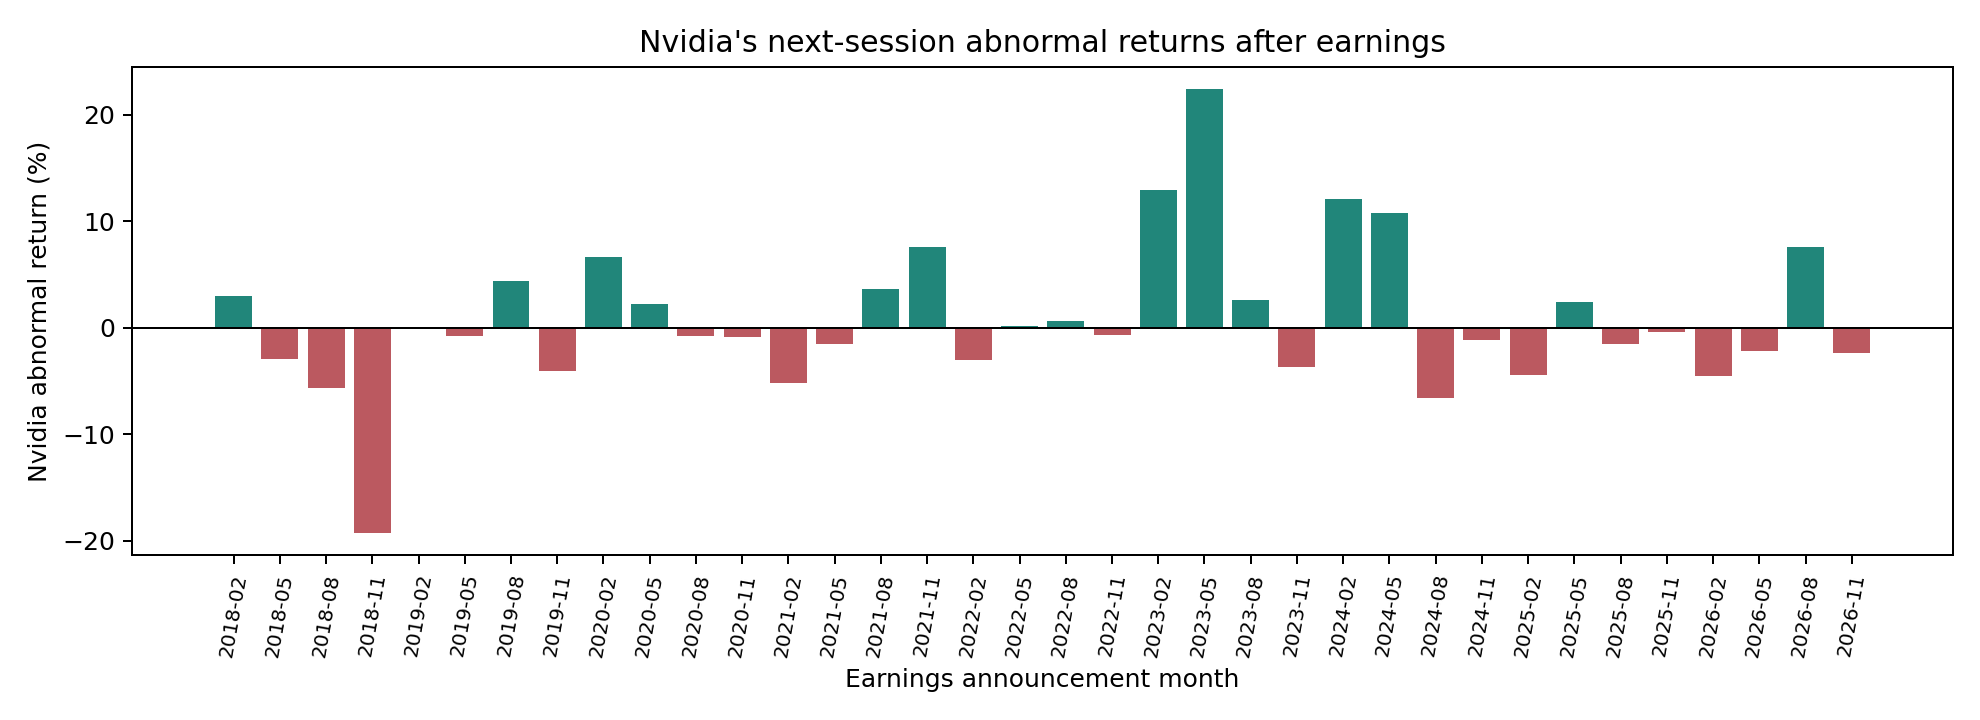

In [4]:
all_us = event_study(us_prices, events, tickers=firm_tickers + ["NVDA"], benchmark="SPY")
if all_us.empty or not all_us.ticker.eq("NVDA").any():
    raise ValueError("Too little price history to estimate Nvidia event reactions. Check data collection.")
all_us.to_csv(PROCESSED / "us_event_returns.csv", index=False)
plot_nvda_reactions(all_us, FIGURES / "01_nvda_earnings_reactions.png")

display(all_us.loc[all_us.ticker.eq("NVDA"),
                   ["announcement_date", "event_date", "abnormal_return"]].tail(8))
nvda_reactions = all_us.loc[all_us.ticker.eq("NVDA")].abnormal_return
print(f"Nvidia: {len(nvda_reactions)} usable events; median absolute AR = {100*nvda_reactions.abs().median():.2f}%")
display(Image(filename=str(FIGURES / "01_nvda_earnings_reactions.png")))

### Interpretation of Nvidia's Earnings Shocks

* **Substantial event-day volatility:** Across all **36 usable earnings announcements** (2018–2026), Nvidia's median absolute next-session abnormal return is 3.00%, confirming that earnings releases act as major, discrete information shocks rather than routine trading days.
* **Regime shift in reaction magnitude:** The bar chart highlights two distinct eras. Aside from a sharp -19% drop in November 2018 (following the crypto-mining inventory overhang), pre-2023 reactions typically stayed within $\pm 5\%$. Starting in early 2023—highlighted by massive positive surges in February 2023 (+13%), May 2023 (+22%), February 2024 (+12%), and May 2024 (+11%)—Nvidia's earnings became primary market-moving catalysts for the broader AI ecosystem.
* **Recent normalization:** Over the most recent announcements in 2025–2026, reactions have moderated (ranging from -4.55% on February 26, 2026 to +7.55% on August 27, 2026), reflecting higher baseline expectations priced in ahead of releases.

### H1 - Revealed exposure differs across firms


We now compare each stock's abnormal return to Nvidia's abnormal return on the same announcement. Each slope is estimated with an intercept; stocks with fewer than eight usable events are excluded instead of being assigned a slope of zero.

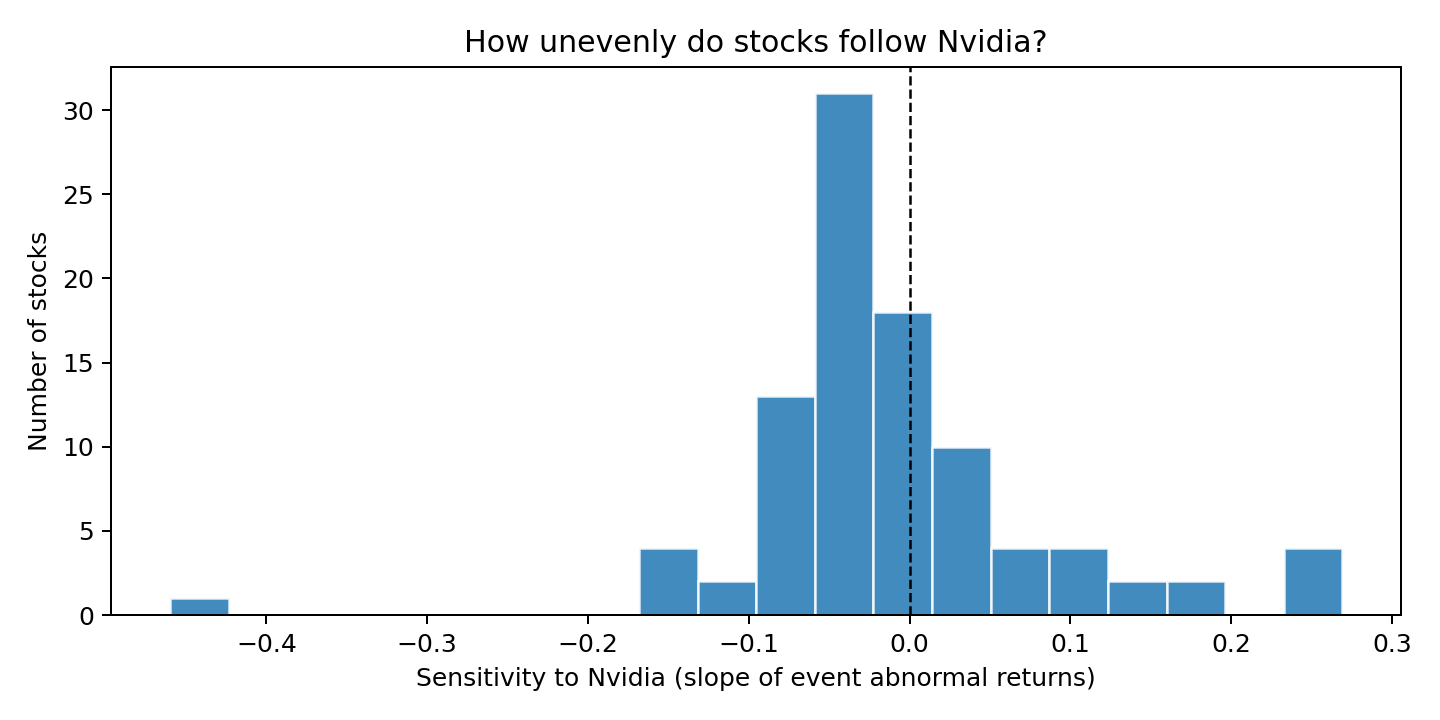

Firms with an estimable slope: 95
Median sensitivity: -0.025
Share with positive sensitivity: 34.7%


,ticker,sensitivity,n_events,r
82,SNPS,0.269100,36,0.532141
7,ALAB,0.251548,8,0.325653
58,MPWR,0.238762,36,0.522430
10,AMD,0.236289,36,0.539904
60,MRVL,0.180129,36,0.480063
15,ASML,0.169484,36,0.578567
21,CDNS,0.140808,36,0.494283
16,AVGO,0.135607,36,0.509815
9,AMAT,0.120456,36,0.273379
63,MU,0.100745,36,0.297016


,ticker,sensitivity,n_events,r
81,SHOP,-0.081781,36,-0.229375
19,BKR,-0.089783,36,-0.329210
85,TMUS,-0.090207,36,-0.468760
80,SBUX,-0.096042,36,-0.538699
31,DDOG,-0.103030,26,-0.210838
30,DASH,-0.134179,21,-0.249912
44,INTC,-0.145304,36,-0.535169
77,RKLB,-0.157024,22,-0.260048
13,APP,-0.162626,20,-0.433364
14,ARM,-0.459913,10,-0.311859


In [5]:
firm_panel = attach_nvda_shocks(all_us)
firm_slopes = sensitivity_by_stock(firm_panel, min_events=settings.min_events_per_slope)
firm_slopes = firm_slopes.sort_values("sensitivity", ascending=False)
if len(firm_slopes) < 5:
    raise ValueError("Insufficient firm slopes. Check histories and event dates.")
firm_slopes.to_csv(PROCESSED / "firm_sensitivity.csv", index=False)
plot_sensitivity_distribution(firm_slopes, FIGURES / "02_firm_sensitivity_histogram.png")
display(Image(filename=str(FIGURES / "02_firm_sensitivity_histogram.png")))

print("Firms with an estimable slope:", len(firm_slopes))
print("Median sensitivity:", round(firm_slopes.sensitivity.median(), 3))
print("Share with positive sensitivity:", f"{100*firm_slopes.sensitivity.gt(0).mean():.1f}%")
display(firm_slopes[["ticker", "sensitivity", "n_events", "r"]].head(10))
display(firm_slopes[["ticker", "sensitivity", "n_events", "r"]].tail(10))

### Interpretation of H1: Cross-Firm Sensitivity Distribution

The results show considerable differences in how companies respond to Nvidia's earnings announcements. Out of the 100 firms considered, 95 have enough observations to estimate a sensitivity coefficient. The estimates range from -0.460 for ARM to +0.269 for Synopsys, with a median of -0.025. Only 34.7% of firms have a positive sensitivity suggesting that positive co-movement with Nvidia is concentrated in a relatively small group rather than being common across the entire sample.

Looking more closely at the firms with the highest positive sensitivities, we find several companies involved in semiconductors and AI infrastructure. These include Synopsys (0.269), Astera Labs (0.252), Monolithic Power Systems (0.239), AMD (0.236), Marvell (0.180), and ASML (0.169). This pattern is interesting because these companies operate in industries closely connected to Nvidia's business. However, their positive coefficients indicate co-movement not necessarily a direct effect of Nvidia's announcements on their stock prices.

At the other end of the distribution, some companies have negative estimated sensitivities, including Intel (-0.145), Starbucks (-0.096), and T-Mobile (-0.090). These negative coefficients indicate that their abnormal returns tended to move in the opposite direction to Nvidia's across the earnings events considered. However, we cannot conclude from these estimates alone that the pattern reflects competition or investors shifting money between sectors.

We should also be careful when comparing companies with different trading histories. For example, Astera Labs has only 8 usable earnings observations and ARM has 10, while firms such as Synopsys and AMD have 36. Sensitivities estimated from fewer observations may be less stable, particularly when a small number of events have unusually large returns.

Overall, the results provide descriptive support for H1. Firms differ substantially in their estimated sensitivity to Nvidia and some of the strongest positive relationships appear among semiconductor and AI infrastructure companies. However, these patterns should not be interpreted as proof of causality or statistical significance for every individual firm.

## 4. Do the AI labels predict sensitivity ? (H2)

To test **H2**, we regress each firm's estimated Nvidia sensitivity slope ($b_i$) on observable measures of AI and technology exposure: ICB sector classifications (`technology_label`, `semiconductor_label`), pre-cutoff R&D intensity (`rd_revenue`, computed from SEC filings prior to November 30, 2022 to avoid hindsight bias), and historical market beta (`historical_market_beta`) as a baseline systematic-risk control.

We estimate the cross-sectional OLS model using heteroskedasticity-robust (HC3) standard errors and evaluate only variables with sufficient non-missing coverage across our sample.

In [6]:
# we estimate pre-november 2022 market betas
beta_controls = market_betas_before_cutoff(us_prices)
label_controls = labels.merge(beta_controls, on="ticker", how="left", validate="one_to_one")

# here we run the cross-sectional OLD regression with HC3 robust standard errors on covariates with sufficient coverage
model, sample, variables = cross_section_regression(firm_slopes, label_controls)
print("Variables with sufficient coverage:", variables)

if model is None:
    print("Insufficient complete, non-collinear observations for a reliable H2 regression.")
    print("Collect SEC facts / issuer holdings, or interpret the sector-only descriptive tables.")
else:
    print(f"H2 regression sample: {int(model.nobs)} firms")
    print(model.summary())
    results = pd.DataFrame({"coefficient": model.params, "robust_se": model.bse,
                            "p_value": model.pvalues})
    results.to_csv(PROCESSED / "h2_coefficients.csv")

# we compute median Nvidia sensitivity grouped by ICB sector across all 95 estimable firms
sector_comparison = firm_slopes.merge(labels[["ticker", "sector"]], on="ticker", how="left")
sector_table = (sector_comparison.groupby("sector", dropna=False)
                .agg(n_firms=("ticker", "count"), median_sensitivity=("sensitivity", "median"))
                .sort_values("median_sensitivity", ascending=False))
display(sector_table)

Variables with sufficient coverage: ['semiconductor_label', 'technology_label', 'rd_revenue', 'historical_market_beta']
H2 regression sample: 57 firms
                            OLS Regression Results                            
Dep. Variable:            sensitivity   R-squared:                       0.292
Model:                            OLS   Adj. R-squared:                  0.237
Method:                 Least Squares   F-statistic:                     5.169
Date:                Sat, 21 Nov 2026   Prob (F-statistic):            0.00139
Time:                        23:20:01   Log-Likelihood:                 66.237
No. Observations:                  57   AIC:                            -122.5
Df Residuals:                      52   BIC:                            -112.3
Df Model:                           4                                         
Covariance Type:                  HC3                                         
                             coef    std err          z    

,n_firms,median_sensitivity
sector,,
Technology,44,0.022656
Basic Materials,1,-0.022844
Consumer Discretionary,15,-0.030526
Health Care,10,-0.039521
Industrials,11,-0.040952
Utilities,4,-0.055514
Consumer Staples,5,-0.055706
Telecommunications,3,-0.075714
Energy,2,-0.077453


### Interpretation of H2: Cross-Sectional Regression and Sector Patterns

The regression includes **57 firms** for which the required R&D data and historical market beta estimates are available. The model explains 
29.2% of the variation in Nvidia sensitivity (R² = 0.292, adjusted R² = 0.237). The overall regression is statistically significant (F = 5.169, p = 0.0014), suggesting that the explanatory variables considered together, are related to differences in Nvidia sensitivity.

The clearest finding concerns **technology-sector classification**. After controlling for the other variables, firms belonging to the ICB Technology sector have an estimated sensitivity that is 0.0749 higher, on average, than firms outside this sector. This relationship is statistically significant (p = 0.002), making technology-sector membership the strongest individual predictor in our model.

However, the results are less convincing for the more specific indicators of AI exposure. The semiconductor indicator has a positive coefficient of 0.0594, but it is not statistically significant (p = 0.155). Similarly, R&D intensity has a coefficient of 0.0101 with a p-value of 0.890, providing little evidence of a relationship once the other variables are taken into account.

One possible explanation is that **R&D expenditure is not specific to artificial intelligence**. Companies invest in research for many different reasons, so a high R&D-to-revenue ratio does not necessarily indicate greater exposure to Nvidia or the AI industry. The semiconductor indicator may also overlap with the broader technology classification, making their separate effects harder to identify.

Historical market beta has a negative estimated coefficient of -0.0236, but it is not statistically significant (p = 0.626). We therefore cannot conclude from this model that general market sensitivity explains the differences in Nvidia sensitivity.

**Overall, H2 receives partial support.** Broad technology-sector membership is positively associated with Nvidia sensitivity, but R&D intensity and semiconductor classification do not provide statistically significant additional evidence in this specification.

These findings should be interpreted with caution. The regression is based on only 57 firms, and the sensitivity coefficients used as the dependent variable are themselves estimates. Furthermore, the analysis identifies statistical associations rather than causal relationships. Our results suggest that a company's industry classification may be more informative than its general R&D spending when assessing its sensitivity to Nvidia's earnings announcements.

## 5. Did the pattern change after ChatGPT? (H3)

The cutoff is the actual public launch date, **30 November 2022**. November 2022 Nvidia earnings are therefore in the pre-period; February 2023 begins the post-period. 
We estimate slopes independently in both periods, so there are fewer events on each side.

Firms estimated in both periods: 86
Median change in sensitivity: -0.02
Share with increased slope: 38.4%


period,Post,Pre,difference_post_minus_pre
ticker,,,
MPWR,0.371694,0.053553,0.318141
AVGO,0.218031,-0.008843,0.226874
CDNS,0.209273,-0.012054,0.221327
PDD,-0.003900,-0.223136,0.219236
LITE,0.124091,-0.072734,0.196824
AMAT,0.200285,0.007395,0.192890
KLAC,0.147186,-0.033967,0.181152
SNPS,0.321166,0.150833,0.170333
ALNY,-0.012281,-0.181181,0.168900


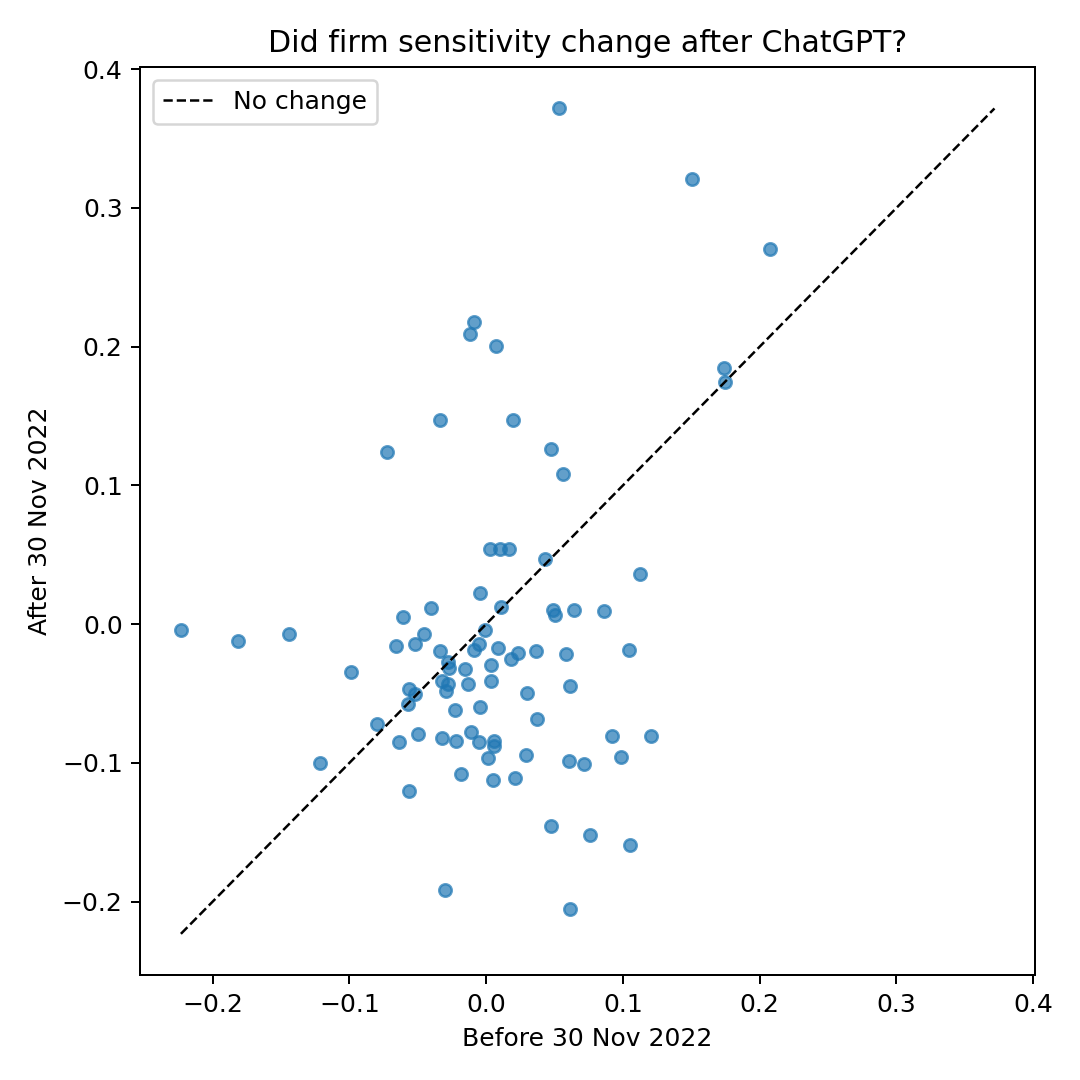

In [7]:
# we estimate pre and post ChatGPT slopes separately
firm_period_slopes = pre_post_sensitivity(firm_panel, cutoff=settings.cutoff_chatgpt,
                                          min_events=settings.min_events_per_slope)

# we keep only the firms with enough events in both periods
wide = firm_period_slopes.pivot(index="ticker", columns="period", values="sensitivity").dropna()
if {"Pre", "Post"}.issubset(wide.columns) and len(wide) >= 3:
    wide["difference_post_minus_pre"] = wide["Post"] - wide["Pre"]
    print("Firms estimated in both periods:", len(wide))
    print("Median change in sensitivity:", round(wide.difference_post_minus_pre.median(), 3))
    print("Share with increased slope:", f"{100*wide.difference_post_minus_pre.gt(0).mean():.1f}%")
    display(wide.sort_values("difference_post_minus_pre", ascending=False).head(10))
    plot_pre_post(firm_period_slopes, FIGURES / "03_sensitivity_pre_post.png")
    display(Image(filename=str(FIGURES / "03_sensitivity_pre_post.png")))
    wide.to_csv(PROCESSED / "firm_pre_post.csv")
else:
    print("Not enough pre/post events. Check the date coverage before interpreting H3.")

### What the pre/post comparison tells us about H3

The comparison covers **86 firms** with enough observations to estimate Nvidia sensitivity both before and after ChatGPT's launch on November 30, 2022.

Contrary to what we initially expected, the results do not show a general increase in sensitivity across the sample. The median change is
-0.020, and only **38.4% of firms have a higher estimated sensitivity in the post-ChatGPT period**. This suggests that the growing attention surrounding AI did not translate into stronger co-movement with Nvidia for most companies.

However, the overall figures hide some important differences between firms. Several companies involved in semiconductors and AI infrastructure experienced substantial increases. For example, Monolithic Power Systems (MPWR) went from a sensitivity of 0.054 before ChatGPT to 0.372 afterward, while Broadcom (AVGO) increased from -0.009 to 0.218.

These examples suggest that the increase in Nvidia sensitivity may have been concentrated among certain hardware and semiconductor companies rather than spread across the market. This distinction matters because companies participating directly in AI infrastructure may be affected differently from businesses that are simply classified as technology firms.

Nevertheless, we should be careful when interpreting these changes. The two periods contain relatively few Nvidia earnings announcements, making the estimated sensitivities less precise. Moreover, ChatGPT's launch was not the only important development during this period. Interest rates, technology-sector valuations, Nvidia's market importance, and semiconductor industry conditions also changed.

**Overall, H3 is not supported at the aggregate level.** Although some AI-related hardware companies became more sensitive to Nvidia after November 2022, the majority of firms did not. Our results therefore point to a selective change rather than a general increase in market sensitivity. The before-and-after comparison cannot establish that ChatGPT caused these differences.

### Descriptive PCA: are stocks moving more together ?

For each calendar year, the first principal component is fitted to standardized daily stock returns. We require at least 90% annual price coverage per stock and 120 trading days per year. The remaining small gaps are filled with that year's sample mean **after standardization**, a limitation that we report rather than hide.

,year,pc1_variance_share,n_stocks,n_days
0,2018,0.411201,82,251
1,2019,0.333618,84,252
2,2020,0.538224,86,253
3,2021,0.313975,90,252
4,2022,0.495785,92,251
5,2023,0.294842,93,250
6,2024,0.239992,94,252
7,2025,0.321911,96,250
8,2026,0.199221,98,224


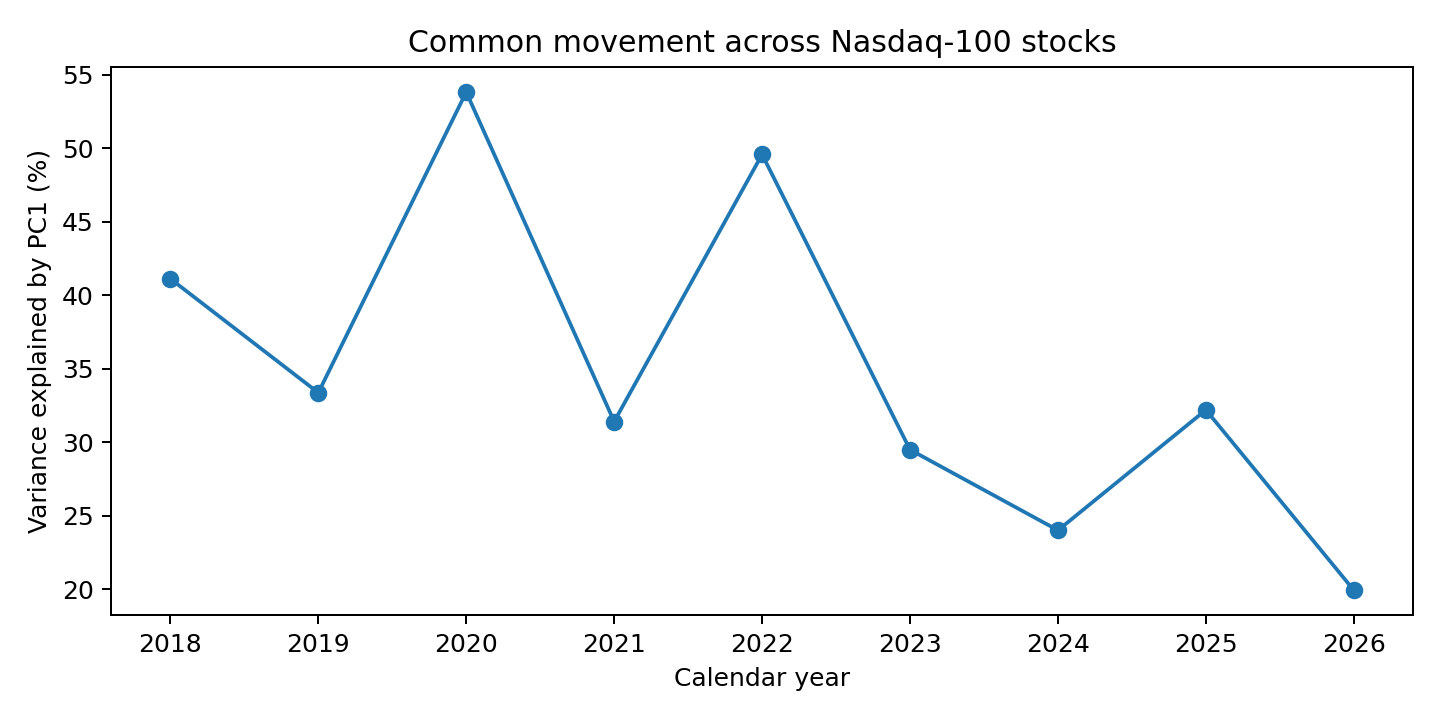

Figure saved: 04_pca_common_movement.png


In [8]:
# we compute annual PC1 variance share across stocks with at least 90% trading day coverage
pca_table = yearly_pca(us_prices, firm_tickers)
if not pca_table.empty:
    display(pca_table)
    plot_pca(pca_table, FIGURES / "04_pca_common_movement.png")
    display(Image(filename=str(FIGURES / "04_pca_common_movement.png")))
    pca_table.to_csv(PROCESSED / "yearly_pca.csv", index=False)
    print("Figure saved: 04_pca_common_movement.png")
else:
    print("PCA requires more complete price histories.")

### What the yearly PCA shows

The PCA (principal component analysis) results provide another perspective on how stock returns move together over time. The first principal component explains a particularly large share of return variation in 2020 (53.8%) and 2022 (49.6%). This share is lower in 2023 (29.5%), 2024 (24.0%) and 2026 (19.9%).

One possible interpretation is that market-wide movements were more important during periods of major economic uncertainty, particularly the COVID-19 pandemic and the market downturn in 2022. In the later years, stock returns appear to be less dominated by a single common component.

However, these results do not necessarily mean that companies became less connected to one another. The PCA measures how much variation is captured by the main statistical component, but it does not identify the economic forces behind that variation.

There are also some limitations to this comparison. The number of firms included in the analysis changes across years depending on the availability of historical prices. In addition, 2026 is not a complete calendar year in our dataset. These differences can affect the proportion of variance explained.

Overall, the PCA suggests that the structure of market co-movement has changed over time. Nevertheless, **it does not provide direct evidence that ChatGPT or the development of AI caused these changes**. We therefore treat it as a descriptive complement to H3, rather than as a separate test of the hypothesis.

## 6. Geography of the AI trade (H4)

We use **US-listed single-country ETFs** (EWT, EWY, EWJ, etc.), not direct daily closes from Taipei, Seoul or Tokyo. This aligns the reaction window with Nvidia's release: the ETFs trade on US hours and may incorporate foreign-market information through US trading and currency movements. It does **not** measure local-index next-session reaction directly. This distinction is central to our interpretation.
`country_etfs.csv` contains the country, ISO3 code and ETF ticker. 

Countries with a usable slope: 29


,country,ticker,sensitivity,n_events
19,Taiwan,EWT,0.062798,36
14,Netherlands,EWN,0.010444,36
1,Indonesia,EIDO,-0.001709,36
10,Japan,EWJ,-0.005317,36
25,India,INDA,-0.009629,36
7,Germany,EWG,-0.014353,36
3,Poland,EPOL,-0.014536,36
2,Israel,EIS,-0.019944,36
27,Thailand,THD,-0.023065,36
13,Malaysia,EWM,-0.023408,36


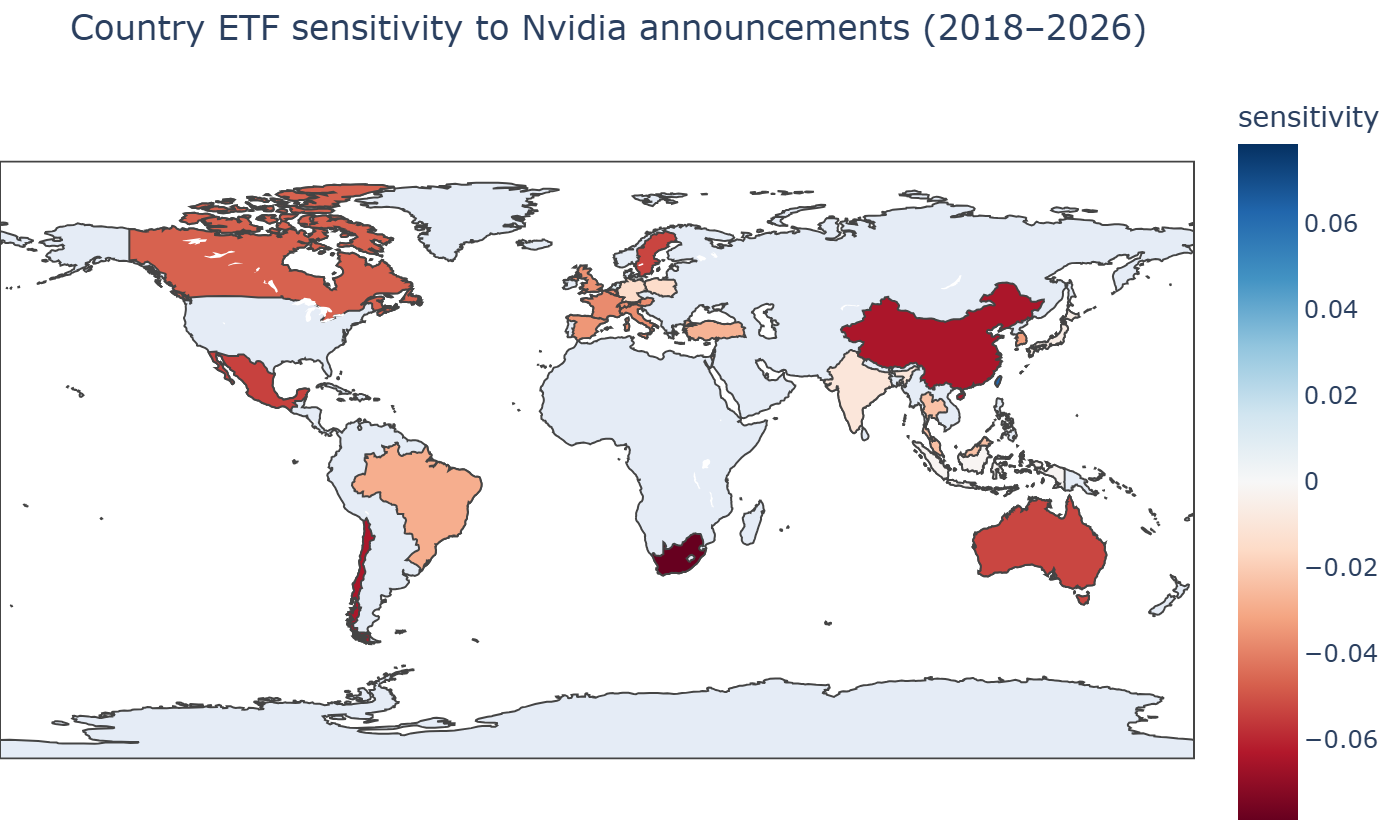

In [9]:
import plotly.express as px

# Align country ETFs with SPY and NVDA on the US trading calendar
combined_country_prices = country_prices.copy()
combined_country_prices["SPY"] = us_prices["SPY"].reindex(combined_country_prices.index)
combined_country_prices["NVDA"] = us_prices["NVDA"].reindex(combined_country_prices.index)
combined_country_prices = combined_country_prices.sort_index()

# Estimate event-window sensitivity for each of the 29 country ETFs
all_country = event_study(combined_country_prices, events, tickers=country_tickers + ["NVDA"], benchmark="SPY")
country_panel = attach_nvda_shocks(all_country)
country_slopes = sensitivity_by_stock(country_panel, min_events=settings.min_events_per_slope)
country_slopes = country_slopes.merge(countries[["etf", "country", "iso3"]], left_on="ticker", right_on="etf", how="left")

print("Countries with a usable slope:", len(country_slopes))
display(country_slopes[["country", "ticker", "sensitivity", "n_events"]].sort_values("sensitivity", ascending=False).head(12))

# Render the static world choropleth map (keep HTML copy in outputs/figures/)
if len(country_slopes) >= 5:
    fig_map = px.choropleth(
        country_slopes,
        locations="iso3",
        color="sensitivity",
        hover_name="country",
        color_continuous_scale="RdBu",
        color_continuous_midpoint=0,
        title="Country ETF sensitivity to Nvidia announcements (2018–2026)",
    )
    fig_map.update_layout(margin=dict(l=0, r=0, t=40, b=0), height=420)
    fig_map.write_html(FIGURES / "05_country_sensitivity_map.html")
    fig_map.write_image(FIGURES / "05_country_sensitivity_map.png", scale=2)
    display(Image(filename=str(FIGURES / "05_country_sensitivity_map.png")))

country_slopes.to_csv(PROCESSED / "country_sensitivity.csv", index=False)

### What the global map shows across 2018–2026

The geographical analysis reveals differences in how country ETFs react to Nvidia's earnings announcements. Among the **29 country ETFs** included in our sample, **Taiwan (EWT)** has the highest estimated sensitivity at **0.0628**, followed by **the Netherlands (EWN)** at **0.0104**. Most other countries have coefficients that are close to zero or slightly negative.

Taiwan's position is particularly interesting given its importance in global semiconductor manufacturing. The country is home to TSMC, one of Nvidia's major manufacturing partners. The Netherlands also plays an important role in the semiconductor industry through companies such as ASML which supplies equipment used in advanced chip production.

These connections offer a possible explanation for why Taiwan and the Netherlands appear among the countries with the highest positive sensitivities. However, the difference between the two is substantial and the estimates should not be interpreted as evidence that the semiconductor industry alone explains their market reactions.

An important limitation is that **we have not directly tested the relationship between country sensitivity and semiconductor trade exposure**. Our analysis compares market reactions across countries but it does not include a statistical regression linking those reactions to semiconductor exports, technology-sector weights, or other measures of participation in the AI supply chain.

Furthermore, we use country ETFs traded in the United States rather than the countries' domestic stock-market indices. Their returns may therefore reflect exchange-rate movements, US trading hours, and broader international market conditions.

**Overall, H4 receives descriptive support, but remains unconfirmed as an explanation of semiconductor supply-chain effects.** We observe meaningful differences between countries, with Taiwan standing out, but the results do not establish that these differences are caused by their exposure to the AI industry.

,country,etf,Pre,Post,diff_post_minus_pre
17,Indonesia,EIDO,-0.070158,0.050727,0.120885
18,Mexico,EWW,-0.096745,-0.016992,0.079753
19,Brazil,EWZ,-0.067173,-0.000083,0.067091
14,India,INDA,-0.050904,0.013944,0.064847
0,Taiwan,EWT,0.022325,0.075909,0.053584
21,Turkey,TUR,-0.061990,-0.021386,0.040604
16,Malaysia,EWM,-0.031418,0.002254,0.033672
27,Chile,ECH,-0.068564,-0.041388,0.027176
15,China,MCHI,-0.078984,-0.055514,0.023470
23,Austria,EWO,-0.042670,-0.024989,0.017681


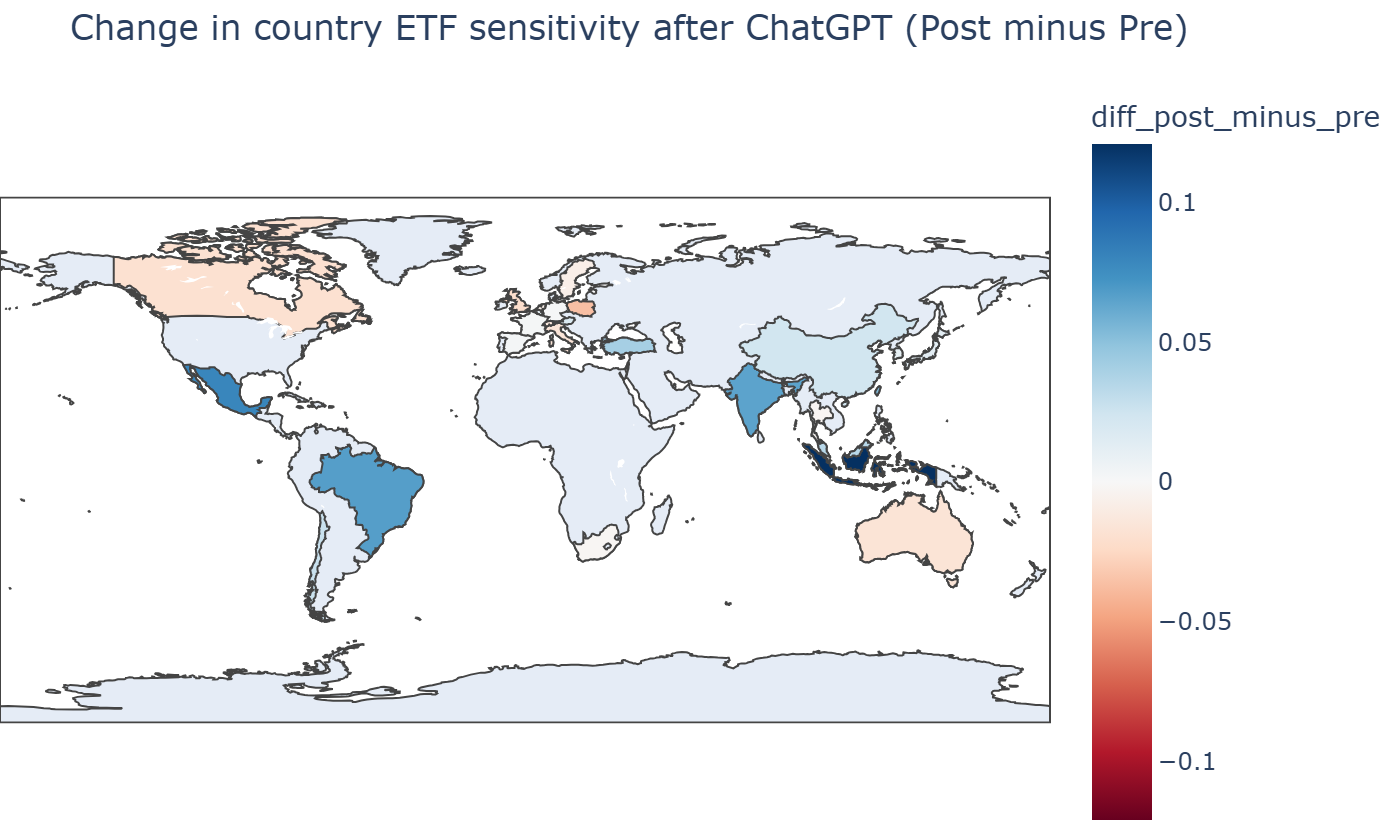

In [10]:
# Compare country-level sensitivities before and after November 30, 2022
country_period = pre_post_sensitivity(
    country_panel,
    cutoff=settings.cutoff_chatgpt,
    min_events=settings.min_events_per_slope
)

if not country_period.empty and {"Pre", "Post"}.issubset(set(country_period.period)):
    country_wide = country_period.pivot(index="ticker", columns="period", values="sensitivity").dropna()
    country_wide["diff_post_minus_pre"] = country_wide["Post"] - country_wide["Pre"]
    country_wide = country_wide.merge(countries[["etf", "country", "iso3"]], left_index=True, right_on="etf", how="left")
    display(country_wide[["country", "etf", "Pre", "Post", "diff_post_minus_pre"]].sort_values("diff_post_minus_pre", ascending=False).head(10))

    # Render static map of post-minus-pre sensitivity changes
    fig_diff = px.choropleth(
        country_wide,
        locations="iso3",
        color="diff_post_minus_pre",
        hover_name="country",
        color_continuous_scale="RdBu",
        color_continuous_midpoint=0,
        title="Change in country ETF sensitivity after ChatGPT (Post minus Pre)",
    )
    fig_diff.update_layout(margin=dict(l=0, r=0, t=40, b=0), height=420)
    fig_diff.write_html(FIGURES / "06_country_pre_post_map.html")
    fig_diff.write_image(FIGURES / "06_country_pre_post_map.png", scale=2)
    display(Image(filename=str(FIGURES / "06_country_pre_post_map.png")))
else:
    print("Country pre/post map requires more complete price coverage.")

### Did international sensitivities shift after ChatGPT?

Splitting the country sample at November 30, 2022 shows that **Taiwan (`EWT`)** became even more tightly linked to Nvidia once the generative AI boom began, jumping from **+0.0223** before ChatGPT to **+0.0759** afterward (an increase of **+0.0536**). 

At the same time, several emerging-market ETFs—such as **Indonesia (`EIDO`, +0.1209 change)**, **Mexico (`EWW`, +0.0798)**, and **Brazil (`EWZ`, +0.0671)**—appear near the top of the `Post minus Pre` difference table simply because they bounced from strongly negative pre-2022 slopes (around `-0.07` to `-0.10`) back toward zero, rather than developing genuine positive exposure to Nvidia. We stop at this descriptive and geographic comparison rather than running a cross-country regression because verified ETF technology weights and bilateral HS 8542 semiconductor trade shares require proprietary factsheets or restricted UN Comtrade API access that fall outside our open, reproducible data pipeline.

## 7. Robustness checks

We carry out three robustness checks to see whether our findings depend too heavily on the choices made in the main analysis.

First, we use **QQQ instead of SPY** as the market benchmark to examine whether the sensitivity estimates change when we account for a different set of market movements. Second, we extend the event window from one trading day to two, allowing for the possibility that some market reactions take longer to appear. Finally, we compare Nvidia's abnormal returns on earnings days with those observed on 200 randomly selected non-earnings dates.

These checks help us assess how stable our results are across different specifications. However, neither SPY nor QQQ completely excludes Nvidia so changing the benchmark does not fully eliminate the overlap between Nvidia and the market index.

In [11]:
# we re estimate slopes using QQQ as the benchmark
qqq_results = event_study(us_prices, events, tickers=firm_tickers + ["NVDA"], benchmark="QQQ")
qqq_slopes = sensitivity_by_stock(attach_nvda_shocks(qqq_results))
two_day_results = event_study(us_prices, events, tickers=firm_tickers + ["NVDA"], benchmark="SPY", window=(0, 1))
two_day_slopes = sensitivity_by_stock(attach_nvda_shocks(two_day_results))

# we compare rank stability across all three specifications
comparison = firm_slopes[["ticker", "sensitivity"]].rename(columns={"sensitivity": "SPY_day0"})
comparison = comparison.merge(qqq_slopes[["ticker", "sensitivity"]].rename(columns={"sensitivity": "QQQ_day0"}), on="ticker")
comparison = comparison.merge(two_day_slopes[["ticker", "sensitivity"]].rename(columns={"sensitivity": "SPY_days0_1"}), on="ticker")
comparison.to_csv(PROCESSED / "robustness_slopes.csv", index=False)
display(comparison[["SPY_day0", "QQQ_day0", "SPY_days0_1"]].corr(method="spearman"))
print("Stocks with all three estimates:", len(comparison))

,SPY_day0,QQQ_day0,SPY_days0_1
SPY_day0,1.000000,0.880305,0.782027
QQQ_day0,0.880305,1.000000,0.617259
SPY_days0_1,0.782027,0.617259,1.000000


Stocks with all three estimates: 95


In [12]:
# we compare Nvidia's abnormal returns on earnings day vs 200 random non earnings dates
actual_shocks, placebo_shocks = placebo_nvda_shocks(
    us_prices, events, n_placebos=200, seed=settings.seed)
if len(actual_shocks) and len(placebo_shocks):
    print(f"Mean |AR| on earnings dates: {100*np.mean(np.abs(actual_shocks)):.2f}%")
    print(f"Mean |AR| on random non-earnings dates: {100*np.mean(np.abs(placebo_shocks)):.2f}%")
    print(f"Number of actual / placebo dates: {len(actual_shocks)} / {len(placebo_shocks)}")
else:
    print("Insufficient data for the placebo exercise.")

Mean |AR| on earnings dates: 4.74%
Mean |AR| on random non-earnings dates: 1.74%
Number of actual / placebo dates: 36 / 200


### What the robustness checks show

The robustness checks suggest that our main findings are reasonably stable, although the results change slightly depending on the methodology used.

When we replace SPY with QQQ as the market benchmark, the estimated firm sensitivities remain strongly related to those obtained in the original analysis, with a **Spearman rank correlation of 0.880**. This suggests that the relative ranking of companies does not change substantially when we use a different market benchmark.

Extending the reaction window from one to two trading days produces a **rank correlation of 0.782** with the original estimates. Although the relationship is slightly weaker, the broad pattern remains relatively consistent.

The placebo exercise provides another useful comparison. Across **36 Nvidia earnings announcements**, the mean absolute abnormal return is **4.74%**, compared with **1.74%** on 200 randomly selected non-earnings dates. Nvidia therefore experienced larger abnormal price movements around its earnings announcements than on the sampled ordinary trading days.

These results strengthen our confidence in the general patterns identified in the analysis. However, they do not establish that every individual firm's sensitivity is statistically significant. In addition, both SPY and QQQ include Nvidia, so changing the benchmark does not completely remove Nvidia's contribution to market-index returns.

Overall, the robustness checks suggest that our findings are not entirely dependent on the original benchmark or event window. Nevertheless, they should be interpreted as evidence of statistical co-movement rather than proof of a causal relationship.

### Summary of Findings

Our results suggest that the relationship between Nvidia and other stock markets is more selective than we initially expected. While some firms show strong positive sensitivity to Nvidia's earnings announcements, this pattern is not shared by the majority of companies in our sample.

**H1 — Differences between firms**

We find substantial variation in Nvidia sensitivity across companies. Among the 95 firms with enough observations, only 34.7% have positive sensitivity coefficients and the median is -0.025. Some of the strongest positive relationships appear among semiconductor and AI infrastructure companies, including Synopsys, Monolithic Power Systems and AMD. These findings provide descriptive support for H1, although they do not establish that every individual relationship is statistically significant.

**H2 — Observable AI exposure**

The cross-sectional regression provides partial support for H2. Technology-sector classification is positively and significantly associated with Nvidia sensitivity, while R&D intensity and the semiconductor indicator are not individually statistically significant after accounting for the other variables. The model explains 29.2% of the variation in sensitivity across the 57 firms included in the regression. This suggests that broad industry classification may be more informative than general R&D spending in our sample.

**H3 — Changes after ChatGPT**

Contrary to our initial expectation, we do not find a general increase in Nvidia sensitivity after November 2022. The median change is -0.020, and only 38.4% of firms show an increase. Nevertheless, several companies involved in semiconductor production and AI infrastructure became more sensitive to Nvidia. This suggests a selective shift rather than a market-wide change. We therefore do not find support for H3 at the overall sample level.

**H4 — International differences**

Country ETFs also display different sensitivities to Nvidia's earnings announcements. Taiwan has the highest estimated positive sensitivity among the 29 countries studied, followed by the Netherlands. These findings are interesting given both countries' roles in the semiconductor industry. However, because we do not directly test the relationship between market sensitivity and semiconductor trade exposure, we cannot confirm that supply-chain participation explains these differences.

**Overall conclusion**

Our analysis highlights an important distinction between being associated with artificial intelligence and showing financial-market sensitivity to Nvidia. A company may belong to the technology sector or invest heavily in research without necessarily reacting strongly to Nvidia's earnings announcements.

The results suggest that industry positioning matters, but they also show that AI exposure is more complex than a simple classification of companies as AI-related or non-AI-related. Our findings provide evidence of differences in market co-movement, while leaving open the question of which economic mechanisms explain them.

### Methodological Limitations

1. **Limited number of events:** Our sample relies on **36 quarterly Nvidia announcements** (and even smaller sub-samples for recent IPOs or pre/post splits), which limits the statistical precision of individual slope estimates.
2. **Survivorship and hindsight bias:** Using a 2026 Nasdaq-100 constituent list and contemporary ICB sector labels introduces survivorship bias, and while SEC R&D ratios were anchored prior to November 2022 where possible, accounting filings still postdate the earliest 2018–2021 earnings events.
3. **Correlation rather than causation:** Nvidia's earnings releases coincide with broader semiconductor news and macroeconomic conditions; controlling for `SPY` or `QQQ` removes market-wide swings but does not isolate a purely causal spillover.
4. **Market-implied reactions vs. true earnings surprises:** Using Nvidia's next-session abnormal return captures how the market reacted relative to priced-in expectations, not the numerical EPS surprise relative to consensus analyst forecasts.
5. **US-listed international proxies:** Single-country ETFs (`EWT`, `EWN`, etc.) trade in US dollars during New York market hours, meaning their returns blend foreign equity repricing with USD exchange-rate movements and US trading-hour spillovers rather than local exchange closes.
6. **Imperfect exposure proxies:** General R&D spending is not exclusively AI investment, ICB classifications differ from GICS sectors, and missing proprietary ETF holdings prevented us from testing thematic fund membership directly.
7. **Unequal stock histories in PCA:** Because recently listed stocks enter the panel later in the 2018–2026 window, the eligible universe for the annual PCA expands from 82 to 98 firms over time, which can affect year-to-year variance comparisons.